# Module 13.1 — Classification Problems 🧠

In NLP, text classification means assigning one or more categories (labels) to a piece of text.

For example, given a customer review:

> "The food was excellent, but the service was slow."

A model might classify it as positive, negative, or potentially both, depending on the task's definition.

There are three main classification setups: binary, multiclass, and multilabel classification.

## 1. Binary classification


Definition: Each input is assigned to one of exactly two possible classes.

Examples:

- Spam vs. not spam
- Positive vs. negative sentiment
- Fraudulent vs. legitimate message

Example:

| Input text                  | Predicted label |
| --------------------------- | --------------- |
| "I love this phone!"        | Positive        |
| "The battery is terrible."  | Negative        |
| "Excellent camera quality." | Positive        |

### How it works

The model estimates the probability of a class. For a binary task, a sigmoid output is a common choice.

\\[ P(y=1\mid x)=\sigma(z)=\frac{1}{1+e^{-z}} \\]

If the predicted probability exceeds a chosen threshold, such as \\(0.5\\), the model predicts class 1; otherwise, it predicts class 0.

NLP application: Email spam detection and binary sentiment analysis.

## 2. Multiclass classification


Definition: Each input belongs to exactly one class among three or more mutually exclusive classes.

NLP examples:

- News: Sports, Politics, Technology
- Sentiment: Positive, Negative, Neutral
- Intent: Greeting, Complaint, Enquiry

Example:

| Input text                      | Predicted label |
| ------------------------------- | --------------- |
| "India won the cricket match."  | Sports          |
| "Parliament passed a new bill." | Politics        |
| "The new processor is faster."  | Technology      |

### How it works

A common approach is a softmax output layer, which converts class logits into probabilities that sum to 1.

\\[ P(y=i\mid x)=\frac{e^{z_i}}{\sum\_{j=1}^{C}e^{z_j}} \\]

Here, \\(C\\) is the number of classes and \\(z_i\\) is the logit for class \\(i\\).

For example:

| Class      | Predicted probability |
| ---------- | --------------------- |
| Sports     | 0.80                  |
| Politics   | 0.05                  |
| Technology | 0.15                  |

The model predicts Sports, the class with the highest probability.

NLP application: Automatically categorizing news articles, customer queries and support tickets.

## 3. Multilabel classification

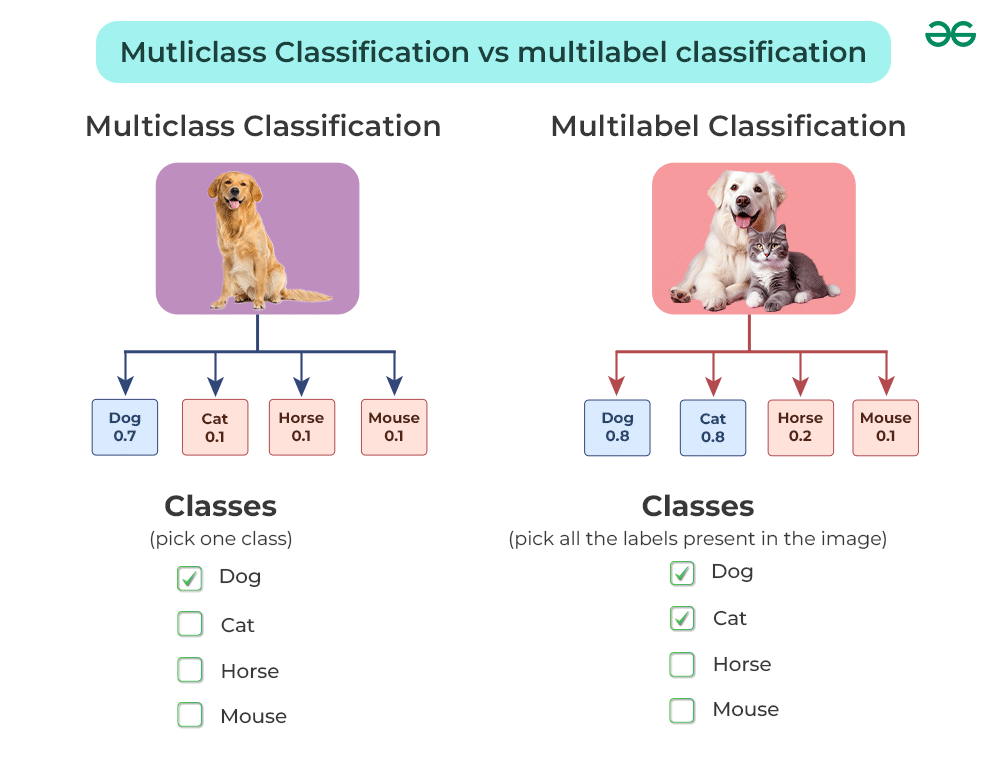

Online image: one input can have multiple labels

Definition: A single input can belong to multiple labels simultaneously.

NLP examples:

- Review tagged as Food, Service and Price
- News article tagged as Politics and Economy
- Support ticket tagged as Payment and Urgent

Example:

| Input text                               | Predicted labels         |
| ---------------------------------------- | ------------------------ |
| "Great food, but expensive."             | Food, Price              |
| "Fast delivery and excellent packaging." | Delivery, Packaging      |
| "The app crashes during payment."        | Technical issue, Payment |

### How it works

A common approach uses one sigmoid output per label, allowing each label to be predicted independently.

\\[ P(y_i=1\mid x)=\sigma(z_i) \\]

Example:

| Label   | Probability | Predicted? |
| ------- | ----------- | ---------- |
| Food    | 0.95        | Yes        |
| Service | 0.20        | No         |
| Price   | 0.85        | Yes        |

Using a threshold of 0.5, the model predicts Food and Price.

Unlike softmax, these probabilities do not have to sum to 1.

NLP application: Document tagging, issue categorization, content moderation and customer feedback analysis.

## 4. Key differences

| Feature                   | Binary               | Multiclass    | Multilabel                     |
| ------------------------- | -------------------- | ------------- | ------------------------------ |
| Number of possible labels | 2                    | 3 or more     | 2 or more                      |
| Labels per input          | One                  | Exactly one   | One or more                    |
| Typical output            | Sigmoid              | Softmax       | Multiple sigmoid outputs       |
| Common loss               | Binary cross-entropy | Cross-entropy | Binary cross-entropy per label |
| Example                   | Spam detection       | News category | Document tags                  |

## 5. Must-know implementation concepts

Since you already know Deep Learning, focus on the differences in output layers and targets rather than revisiting neural-network fundamentals.

| Problem    | Typical target format | Typical PyTorch loss |
| ---------- | --------------------- | -------------------- |
| Binary     | Single binary target  | `BCEWithLogitsLoss`  |
| Multiclass | Integer class ID      | `CrossEntropyLoss`   |
| Multilabel | Multi-hot vector      | `BCEWithLogitsLoss`  |

Important: PyTorch's `CrossEntropyLoss` expects raw logits, not softmax probabilities. Similarly, `BCEWithLogitsLoss` expects raw logits, not sigmoid outputs.

### What you should remember

1. Binary classification chooses between two classes.
2. Multiclass classification chooses exactly one class from several options.
3. Multilabel classification allows several labels for the same input.
4. Softmax is common for multiclass; sigmoid outputs are common for binary and multilabel tasks.
5. The problem definition determines the output format, loss function and evaluation strategy.

---